<a href="https://colab.research.google.com/github/alandevnp-dot/Biochem_assignment/blob/main/Biochemistry_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# For working with CSV files
import pandas as pd
import numpy as np

# For Model training
from sklearn.model_selection import GroupShuffleSplit, cross_val_predict
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.model_selection import RandomizedSearchCV
from sklearn.inspection import permutation_importance

# For graphs and visual data
from matplotlib import pyplot as plt

# For dealing with chemical compounds and data
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem import rdMolDescriptors
db = pd.read_excel("TLC_dataset.xlsx")

In [ ]:
def calculate_descriptors(smiles):
  mol = Chem.MolFromSmiles(smiles)
  if mol == None:
    return None
  return {
      "MW": Descriptors.MolWt(mol),
      "LogP": Descriptors.MolLogP(mol),
      "TPSA": Descriptors.TPSA(mol),
      "HBD": rdMolDescriptors.CalcNumHBD(mol),
      "HBA": rdMolDescriptors.CalcNumHBA(mol),
      "Rotatablebonds": rdMolDescriptors.CalcNumRotatableBonds(mol),
      "AromaticRings": rdMolDescriptors.CalcNumAromaticRings(mol)

  }

In [ ]:
unique_compounds = db[["COMPOUND_ID","COMPOUND_SMILES"]].drop_duplicates("COMPOUND_ID")
descriptor_data = unique_compounds["COMPOUND_SMILES"].apply(calculate_descriptors)

descriptor_db = pd.DataFrame(data = descriptor_data.tolist(), index = unique_compounds.index)
unique_compounds = pd.concat([unique_compounds, descriptor_db], axis = 1)

db = db.merge(unique_compounds.drop(columns = "COMPOUND_SMILES"), on = "COMPOUND_ID", how = "left")

In [ ]:
molecular_features = ["MW","LogP","TPSA","HBD","HBA","Rotatablebonds","AromaticRings"]
solvent_features = ["H","EA","DCM","MeOH","Et2O"]
features = molecular_features + solvent_features
X = db[features]
y = db["Rf"]

In [ ]:
splitter = GroupShuffleSplit(test_size = 0.2, n_splits = 1, random_state= 42)
train_idx, test_idx = next(splitter.split(X, y, groups = db["COMPOUND_ID"]))

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]


In [ ]:
model = RandomForestRegressor(
    n_estimators = 200,
    max_depth = None,
    random_state = 42,
    n_jobs = -1
)
model.fit(X_train, y_train)

RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)

In [ ]:
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = mse ** 0.5

print(f"Root Mean Squared Error: {rmse}")
print(f"R-squared: {r2}")
print(f"Mean Absolute Error: {mae}")

Root Mean Squared Error: 0.1910990664126625
R-squared: 0.6841646270944727
Mean Absolute Error: 0.11667035183775412


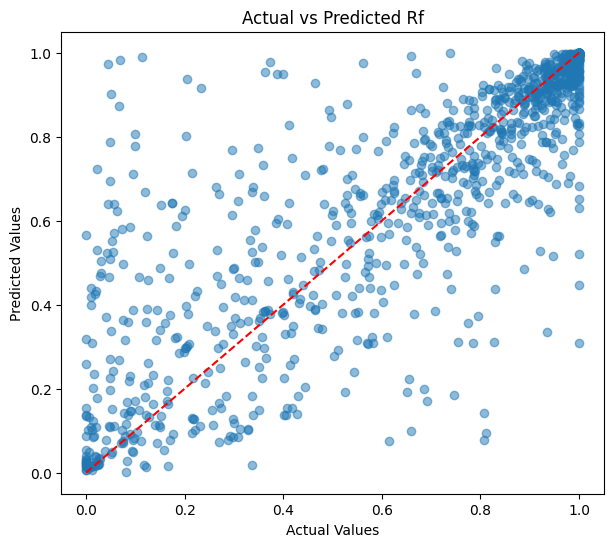

In [ ]:
plt.figure(figsize = (7, 6))
plt.scatter(y_test, y_pred, alpha = 0.5)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Rf")
plt.plot([0,1], [0,1], linestyle = "--", color = "red")
plt.show()


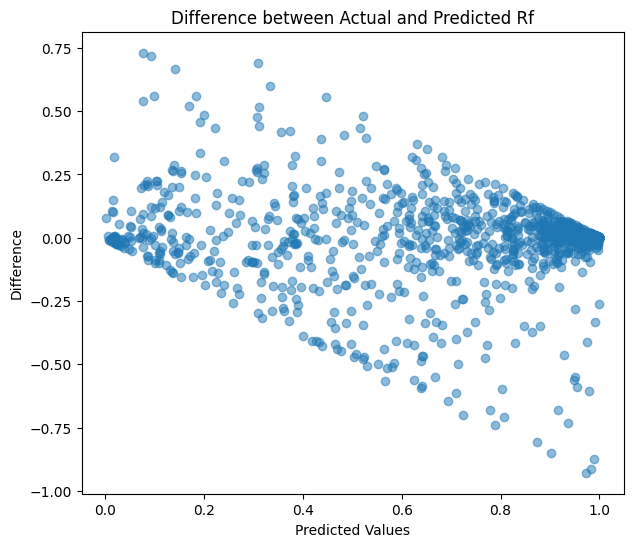

In [ ]:
comparison = pd.DataFrame({"Actual": y_test, "Predicted": y_pred})
comparison["Difference"] = comparison["Actual"] - comparison["Predicted"]

plt.figure(figsize = (7, 6))
plt.scatter(comparison["Predicted"], comparison["Difference"], alpha = 0.5)
plt.xlabel("Predicted Values")
plt.ylabel("Difference")
plt.title("Difference between Actual and Predicted Rf")
plt.show()


In [ ]:
train_pred = model.predict(X_train)
train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, y_pred)

print(f"Train R-squared: {train_r2}")
print(f"Test R-squared: {test_r2}")

Train R-squared: 0.970559061918461
Test R-squared: 0.6841646270944727


In [ ]:
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators = 200,
        max_depth = None,
        random_state = 42,
        n_jobs = -1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators = 200,
        learning_rate = 0.05,
        max_depth = 3,
        random_state = 42
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators = 200,
        max_depth = None,
        random_state = 42,
        n_jobs = -1
    ),
    "Ridge Regression": make_pipeline(
        StandardScaler(),
        Ridge(alpha = 1.0)
    )
}

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

results = []

for name, model in models.items():
  model.fit(X_train, y_train)
  predictions = model.predict(X_test)
  mae = mean_absolute_error(y_test, predictions)
  rmse = mean_squared_error(y_test, predictions) ** 0.5
  r2 = r2_score(y_test, predictions)

  results.append({
      "Model": name,
      "MAE": mae,
      "RMSE": rmse,
      "R2": r2
      })

results_df = pd.DataFrame(results)

print(results_df)

               Model       MAE      RMSE        R2
0      Random Forest  0.116670  0.191099  0.684165
1  Gradient Boosting  0.127797  0.188654  0.692196
2        Extra Trees  0.104902  0.175028  0.735053
3   Ridge Regression  0.170336  0.215684  0.597672


In [ ]:
groups_train = db.iloc[train_idx]["COMPOUND_ID"]
cv = GroupKFold(n_splits=5)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

cv_results = []

for name, model in models.items():
  scores = cross_validate(
      model,
      X_train,
      y_train,
      groups=groups_train,
      cv=cv,
      scoring=scoring,
      n_jobs=-1
    )

  cv_results.append({
      "Model": name,
      "MAE_mean": -scores["test_MAE"].mean(),
      "MAE_std": scores["test_MAE"].std(),
      "RMSE_mean": -scores["test_RMSE"].mean(),
      "RMSE_std": scores["test_RMSE"].std(),
      "R2_mean": scores["test_R2"].mean(),
      "R2_std": scores["test_R2"].std()
    })

cv_df = pd.DataFrame(cv_results)
print(cv_df.round(4))

               Model  MAE_mean  MAE_std  RMSE_mean  RMSE_std  R2_mean  R2_std
0      Random Forest    0.1111   0.0134     0.1685    0.0205   0.7338  0.0533
1  Gradient Boosting    0.1160   0.0087     0.1632    0.0136   0.7511  0.0354
2        Extra Trees    0.1160   0.0160     0.1775    0.0242   0.7036  0.0671
3   Ridge Regression    0.1635   0.0092     0.2054    0.0147   0.6051  0.0573


In [ ]:
param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [1, 2, 3],
    "min_samples_leaf": [1, 2, 4, 8],
    "subsample": [0.7, 0.85, 1.0]
}

gb_search = RandomizedSearchCV(
    estimator=GradientBoostingRegressor(
        random_state=42
    ),
    param_distributions=param_grid,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=GroupKFold(n_splits=5),
    random_state=42,
    n_jobs=-1
)

gb_search.fit(X_train, y_train, groups=groups_train)

RandomizedSearchCV(cv=GroupKFold(n_splits=5, random_state=None, shuffle=False),
                   estimator=GradientBoostingRegressor(random_state=42),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'learning_rate': [0.01, 0.03, 0.05,
                                                          0.1],
                                        'max_depth': [1, 2, 3],
                                        'min_samples_leaf': [1, 2, 4, 8],
                                        'n_estimators': [100, 200, 300, 500],
                                        'subsample': [0.7, 0.85, 1.0]},
                   random_state=42, scoring='neg_root_mean_squared_error')

In [ ]:
rf_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": [1.0, "sqrt", 0.8]
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs = -1
    ),
    param_distributions=rf_grid,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=GroupKFold(n_splits=5),
    random_state=42,
    n_jobs=-1
)

rf_search.fit(X_train, y_train, groups=groups_train)

RandomizedSearchCV(cv=GroupKFold(n_splits=5, random_state=None, shuffle=False),
                   estimator=RandomForestRegressor(n_jobs=-1, random_state=42),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'max_depth': [None, 10, 20, 30],
                                        'max_features': [1.0, 'sqrt', 0.8],
                                        'min_samples_leaf': [1, 2, 4, 8],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [100, 200, 300, 500]},
                   random_state=42, scoring='neg_root_mean_squared_error')

In [ ]:
best_gb = gb_search.best_estimator_
best_rf = rf_search.best_estimator_

for name, model in [
    ("Tuned Gradient Boosting", best_gb),
    ("Tuned Random Forest", best_rf)]:
    predictions = model.predict(X_test)
    print("\n", name)
    print("MAE:",mean_absolute_error(y_test, predictions))
    print("RMSE:",mean_squared_error(y_test, predictions) ** 0.5)
    print("R2:",r2_score(y_test, predictions))


 Tuned Gradient Boosting
MAE: 0.12392719963110088
RMSE: 0.18277957541261705
R2: 0.7110657897469926

 Tuned Random Forest
MAE: 0.11924426454105726
RMSE: 0.18685008896095193
R2: 0.6980533221738563


In [ ]:
importance = permutation_importance(
    best_gb,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

molecular_features = ["MW", "LogP", "TPSA", "HBD", "HBA", "Rotatablebonds", "AromaticRings"]

importance_db = pd.DataFrame({
    "Feature": molecular_features,
    "Importance": importance.importances_mean[
        [features.index(f) for f in molecular_features]
    ],
    "Std": importance.importances_std[
        [features.index(f) for f in molecular_features]
    ]
})

importance_db = importance_db.sort_values(
    by="Importance",
    ascending=False
)

print(importance_db)

          Feature  Importance       Std
2            TPSA    0.053810  0.002750
3             HBD    0.015762  0.001692
1            LogP    0.011295  0.001401
5  Rotatablebonds    0.008358  0.000737
0              MW    0.005394  0.001083
6   AromaticRings    0.004222  0.000750
4             HBA    0.003986  0.000567


In [ ]:
solvent_features = ["H", "EA", "DCM", "MeOH", "Et2O"]

baseline_mae = mean_absolute_error(y_test, best_gb.predict(X_test))
X_shuffled = X_test.copy()
rng = np.random.default_rng(42)
permutation = rng.permutation(len(X_test))

X_shuffled[solvent_features] = (X_test[solvent_features].iloc[permutation].to_numpy())

shuffled_mae = mean_absolute_error(y_test,best_gb.predict(X_shuffled))

print("Baseline MAE:", baseline_mae)
print("MAE after solvent-group permutation:", shuffled_mae)
print("Increase in MAE:", shuffled_mae - baseline_mae)

Baseline MAE: 0.12392719963110088
MAE after solvent-group permutation: 0.2902377137962329
Increase in MAE: 0.16631051416513204


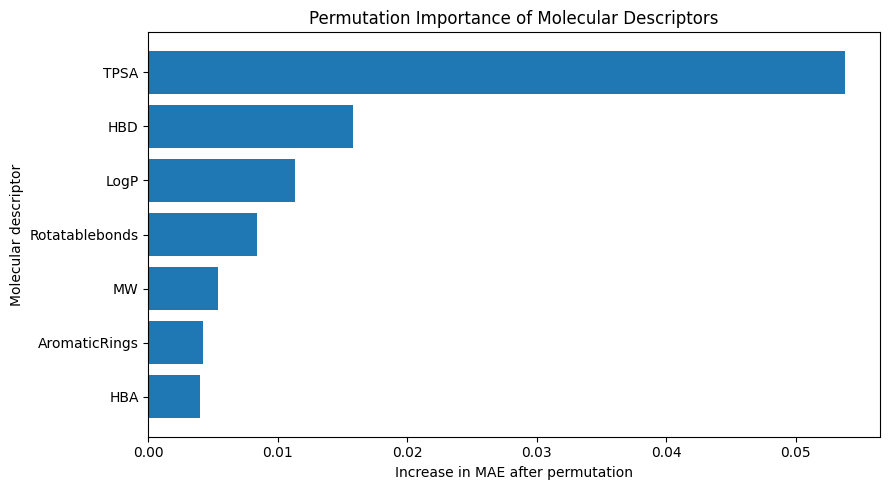

In [ ]:
plt.figure(figsize=(9, 5))

plt.barh(importance_db["Feature"],importance_db["Importance"])

plt.xlabel("Increase in MAE after permutation")
plt.ylabel("Molecular descriptor")
plt.title("Permutation Importance of Molecular Descriptors")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()